<a href="https://colab.research.google.com/github/NicGal-1925/streaming-recommendation-system/blob/main/notebooks/05_feature_engineering_and_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Feature Engineering & Baseline Preference Prediction

This notebook builds and evaluates the first interpretable baseline model for predicting whether a user will rate a movie 4.0 or higher.

The baseline uses movie genre features and the chronological train/test strategy established during preprocessing. Later versions will add rating-history and personalization features for comparison.

## 1. Recreate Prepared Modeling Data

Recreate the validated MovieLens modeling dataset and chronological split needed for this experiment. The preprocessing logic follows the decisions established in `04_preprocessing_and_target.ipynb`.

In [1]:
import pandas as pd
import numpy as np

In [2]:
from google.colab import files

uploaded = files.upload()

Saving movielens_prepared_split.zip to movielens_prepared_split.zip


In [3]:
#load the two CSVs directly from the ZIP
from zipfile import ZipFile

with ZipFile("movielens_prepared_split.zip", "r") as archive:
    with archive.open("train_data.csv") as train_file:
        train_data = pd.read_csv(train_file)

    with archive.open("test_data.csv") as test_file:
        test_data = pd.read_csv(test_file)

print("Training shape:", train_data.shape)
print("Testing shape:", test_data.shape)

Training shape: (80419, 29)
Testing shape: (20417, 29)


In [4]:
#explicitly list the features the model is allowed to use
genre_features = [
    "(no genres listed)",
    "Action", "Adventure", "Animation", "Children",
    "Comedy", "Crime", "Documentary", "Drama",
    "Fantasy", "Film-Noir", "Horror", "IMAX",
    "Musical", "Mystery", "Romance", "Sci-Fi",
    "Thriller", "War", "Western"
]

assert len(genre_features) == 20, "Expected exactly 20 genre features."
assert set(genre_features).issubset(train_data.columns), "Training genres missing."
assert set(genre_features).issubset(test_data.columns), "Testing genres missing."

print("Validated genre features:", len(genre_features))

Validated genre features: 20


In [5]:
#separate inputs (X) from the answer to predict (y)
X_train = train_data[genre_features].copy()
X_test = test_data[genre_features].copy()

y_train = train_data["positive_rating"].copy()
y_test = test_data["positive_rating"].copy()

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (80419, 20)
X_test: (20417, 20)
y_train: (80419,)
y_test: (20417,)


In [6]:
#check that inputs and labels contain valid values before training
for name, X, y in [
    ("Training", X_train, y_train),
    ("Testing", X_test, y_test)
]:
    print(f"\n{name}")
    print("Feature dtypes:", X.dtypes.unique())
    print("Missing feature values:", X.isna().sum().sum())
    print("Missing target values:", y.isna().sum())

    assert X.index.equals(y.index), f"{name}: input/target alignment mismatch"
    assert X.isin([0, 1]).all().all(), f"{name}: invalid genre values"
    assert y.isin([0, 1]).all(), f"{name}: invalid target values"


Training
Feature dtypes: [dtype('int64')]
Missing feature values: 0
Missing target values: 0

Testing
Feature dtypes: [dtype('int64')]
Missing feature values: 0
Missing target values: 0


In [7]:
class_distribution = pd.DataFrame({
    "train_count": y_train.value_counts(),
    "train_percent": y_train.value_counts(normalize=True) * 100,
    "test_count": y_test.value_counts(),
    "test_percent": y_test.value_counts(normalize=True) * 100
}).sort_index()

class_distribution.index.name = "positive_rating"
display(class_distribution)

,train_count,train_percent,test_count,test_percent
positive_rating,,,,
0,41348,51.41571,10908,53.426067
1,39071,48.58429,9509,46.573933


In [8]:
class_distribution = pd.DataFrame({
    "train_count": y_train.value_counts(),
    "train_percent": y_train.value_counts(normalize=True) * 100,
    "test_count": y_test.value_counts(),
    "test_percent": y_test.value_counts(normalize=True) * 100
}).sort_index()

class_distribution.index.name = "positive_rating"
display(class_distribution)

,train_count,train_percent,test_count,test_percent
positive_rating,,,,
0,41348,51.41571,10908,53.426067
1,39071,48.58429,9509,46.573933


In [9]:
majority_class = y_train.value_counts().idxmax()

majority_predictions = np.full(
    shape=len(y_test),
    fill_value=majority_class
)

majority_accuracy = (majority_predictions == y_test).mean()

print("Majority class from training:", majority_class)
print(f"Majority benchmark test accuracy: {majority_accuracy:.2%}")

Majority class from training: 0
Majority benchmark test accuracy: 53.43%


In [10]:
#train logistic regression

from sklearn.linear_model import LogisticRegression

baseline_model = LogisticRegression(max_iter=1000)

baseline_model.fit(X_train, y_train)

print("Training complete.")
print("Number of genre weights:", baseline_model.coef_.shape[1])
print("Iterations used:", baseline_model.n_iter_[0])

Training complete.
Number of genre weights: 20
Iterations used: 17


In [11]:
#generate its predictions on test inputs

y_pred = baseline_model.predict(X_test)

y_probability = baseline_model.predict_proba(X_test)[
    :, list(baseline_model.classes_).index(1)
]

preview = pd.DataFrame({
    "actual_target": y_test.to_numpy(),
    "predicted_target": y_pred,
    "positive_probability": y_probability
})

display(preview.head(10))

,actual_target,predicted_target,positive_probability
0,1,1,0.543825
1,0,0,0.484926
2,1,0,0.397078
3,1,0,0.397078
4,1,0,0.492482
5,0,0,0.397078
6,1,0,0.417297
7,1,0,0.397078
8,1,0,0.498251
9,1,0,0.367226


In [18]:
#calculate and store accuracy

baseline_accuracy = (y_pred == y_test.to_numpy()).mean()

print(f"Majority benchmark accuracy: {majority_accuracy:.2%}")
print(f"Logistic Regression accuracy: {baseline_accuracy:.2%}")
print(
    f"Difference: "
    f"{(baseline_accuracy - majority_accuracy) * 100:+.2f} percentage points"
)

Majority benchmark accuracy: 53.43%
Logistic Regression accuracy: 57.31%
Difference: +3.88 percentage points


In [13]:
#check what mistakes the model is making using a confusion matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

confusion_table = pd.DataFrame(
    cm,
    index=["Actual 0: non-positive", "Actual 1: positive"],
    columns=["Predicted 0: non-positive", "Predicted 1: positive"]
)

display(confusion_table)

,Predicted 0: non-positive,Predicted 1: positive
Actual 0: non-positive,6968,3940
Actual 1: positive,4776,4733


In [14]:
#calculate and store precision

tn, fp, fn, tp = cm.ravel()

baseline_precision = tp / (tp + fp)

print(f"Positive-class precision: {baseline_precision:.2%}")

Positive-class precision: 54.57%


In [15]:
#calculate and store recall

baseline_recall = tp / (tp + fn)

print(f"Positive-class recall: {baseline_recall:.2%}")

Positive-class recall: 49.77%


In [16]:
#calculate and store F1-score

baseline_f1 = (
    2 * baseline_precision * baseline_recall
    / (baseline_precision + baseline_recall)
)

print(f"Positive-class F1-score: {baseline_f1:.2%}")

Positive-class F1-score: 52.06%


In [19]:
#inspect what the model learned about each genre

genre_coefficients = pd.DataFrame({
    "genre": genre_features,
    "coefficient": baseline_model.coef_[0]
}).sort_values("coefficient", ascending=False)

display(genre_coefficients)

,genre,coefficient
3,Animation,0.547870
7,Documentary,0.545574
18,War,0.496183
10,Film-Noir,0.484926
6,Crime,0.357344
8,Drama,0.321431
14,Mystery,0.191659
2,Adventure,0.166905
19,Western,0.159258
13,Musical,0.105439


In [20]:
#collect results into one table

baseline_results = pd.DataFrame([{
    "model": "Logistic Regression",
    "features": "20 movie genres",
    "train_interactions": len(X_train),
    "test_interactions": len(X_test),
    "majority_accuracy": majority_accuracy,
    "accuracy": baseline_accuracy,
    "precision": baseline_precision,
    "recall": baseline_recall,
    "f1": baseline_f1
}])

display(baseline_results)

,model,features,train_interactions,test_interactions,majority_accuracy,accuracy,precision,recall,f1
0,Logistic Regression,20 movie genres,80419,20417,0.534261,0.573101,0.545717,0.497739,0.520625


In [21]:
#save the results, coefficients, and predictions in one downloadable ZIP

test_predictions = test_data[
    ["userId", "movieId", "timestamp", "positive_rating"]
].copy()

test_predictions["predicted_target"] = y_pred
test_predictions["positive_probability"] = y_probability

with ZipFile("baseline_results.zip", "w") as archive:
    archive.writestr(
        "baseline_metrics.csv",
        baseline_results.to_csv(index=False)
    )
    archive.writestr(
        "genre_coefficients.csv",
        genre_coefficients.to_csv(index=False)
    )
    archive.writestr(
        "baseline_test_predictions.csv",
        test_predictions.to_csv(index=False)
    )

files.download("baseline_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

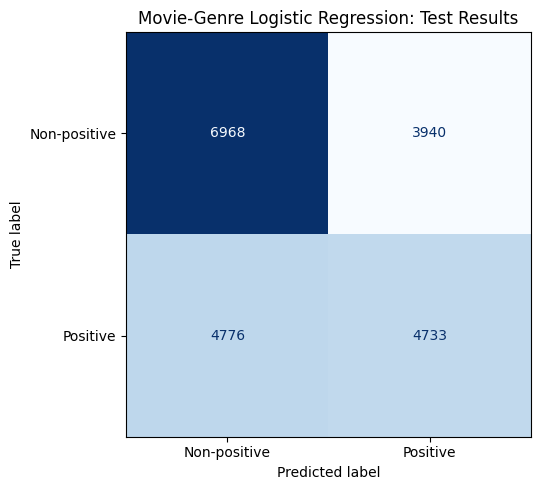

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
#confusion matrix figure for course report

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-positive", "Positive"]
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

ax.set_title("Movie-Genre Logistic Regression: Test Results")
fig.tight_layout()

fig.savefig("baseline_confusion_matrix.png", dpi=300)
plt.show()

files.download("baseline_confusion_matrix.png")

## Baseline Results and Interpretation

Logistic Regression used 20 movie-genre indicators to predict whether
a held-out rating would be 4.0 or higher. It was trained on 80,419
interactions and evaluated on 20,417 interactions using the existing
per-user chronological split.

| Metric | Test result |
|---|---:|
| Majority-class benchmark accuracy | 53.43% |
| Logistic Regression accuracy | 57.31% |
| Positive-class precision | 54.57% |
| Positive-class recall | 49.77% |
| Positive-class F1-score | 52.06% |

Genre features improved accuracy by 3.88 percentage points over always
predicting the training majority class. However, the model identified
only about half of the actual positive ratings.

### Limitations

- The model uses no user-history information. Identical genre inputs
  produce identical predictions for every user.
- Genre coefficients describe learned associations, not causal effects.
- For 130 users, training and test boundary timestamps are equal.
  This documented timestamp-resolution ambiguity is retained.
- These results measure preference classification on observed ratings;
  they do not establish the quality of a ranked recommendation list.

### Reproducibility and Saved Outputs

Notebook 04 exports the prepared training and test tables to
`movielens_prepared_split.zip`. This notebook loads that archive
through a manual upload in a fresh Colab runtime.

Saved outputs include baseline metrics, genre coefficients,
test-interaction predictions, and a confusion-matrix figure.

### Next Experiment

Add features derived from the target user's previous rating history.
Compare against this baseline using the exact same held-out test
interactions. Any model or threshold tuning must use training-side
validation data rather than the test set.